In [11]:
%pip install pandas numpy

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ------------ --------------------------- 3.4/10.9 MB 29.7 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 44.3 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------- ----------------------- 5.2/12.7 MB 27.3 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 32.7 MB/s  0:00:00

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np

# Load the Telco Customer Churn dataset directly from IBM's public GitHub
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Check the size of the dataset and view the first 5 rows
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
# Install the statistical and machine learning libraries we will need
%pip install scipy scikit-learn

import scipy.stats as stats

# 1. Chi-Square Test: Contract Type vs. Churn
contingency_table = pd.crosstab(df['Contract'], df['Churn'])
chi2, p_val_chi, dof, expected = stats.chi2_contingency(contingency_table)

print("--- Chi-Square Test (Contract vs Churn) ---")
print(f"P-value: {p_val_chi}")
if p_val_chi < 0.05:
    print("Conclusion: Contract type has a statistically significant impact on Churn.\n")

# 2. T-Test: Monthly Charges (Churn = Yes) vs (Churn = No)
churn_yes = df[df['Churn'] == 'Yes']['MonthlyCharges']
churn_no = df[df['Churn'] == 'No']['MonthlyCharges']

t_stat, p_val_t = stats.ttest_ind(churn_yes, churn_no, equal_var=False)

print("--- Two-Sample T-Test (Monthly Charges) ---")
print(f"P-value: {p_val_t}")
if p_val_t < 0.05:
    print("Conclusion: There is a statistically significant difference in monthly charges between churned and retained customers.")

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   --- ------------------------------------ 3.4/37.4 MB 23.3 MB/s eta 0:00:02
   ---- ----------------------------------- 3.9/37.4 MB 9.8 MB/s eta 0:00:04
   ----------- ---------------------------- 10.7/37.4 MB 20.0 MB/s eta 0:00:02
   -------------------- ------------------- 19.1/37.4 MB 23.5 MB/s eta 0:00:01
   ------------------------------- -------- 29.4/37.4 MB 28.9 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 30.7 MB/s  0:00:01
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 8.4/8.4 MB 64.8 MB/s  0:00:00

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ----------------------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


--- Chi-Square Test (Contract vs Churn) ---
P-value: 5.863038300673391e-258
Conclusion: Contract type has a statistically significant impact on Churn.

--- Two-Sample T-Test (Monthly Charges) ---
P-value: 8.592449331547067e-73
Conclusion: There is a statistically significant difference in monthly charges between churned and retained customers.


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Fix the hidden text issue in 'TotalCharges' (convert blanks to NaN, then fill with 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan))
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. Drop the 'customerID' column because it has no predictive mathematical value
df_clean = df.drop('customerID', axis=1)

# 3. Convert the target variable 'Churn' into binary (1s and 0s)
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# 4. Convert all other categorical text columns into numbers (Dummy Variables / One-Hot Encoding)
df_encoded = pd.get_dummies(df_clean, drop_first=True)

# 5. Split the data: 80% for Training the model, 20% for Testing its accuracy
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# We use stratify=y to ensure both sets have the exact same proportion of churned customers
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 6. Scale the numerical features so large numbers (TotalCharges) don't overpower small ones (tenure)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")
print("Data cleaning complete. Ready for Machine Learning.")

Training data shape: (5634, 30)
Testing data shape: (1409, 30)
Data cleaning complete. Ready for Machine Learning.


In [16]:
%pip install matplotlib seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------  9.4/9.5 MB 50.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 43.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 56.1 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------- ----------- 5.2/7.3 MB 25.4 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 26.9 MB/s  0:00:00

   ---------------------------------------- 0/8 [pyparsing]
   ---------------------------------------- 0/8 [pyparsing]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1/8 [pillow]
   ----- --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


--- Logistic Regression Performance ---
ROC-AUC Score: 0.8418
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


--- Random Forest Performance ---
ROC-AUC Score: 0.8248
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



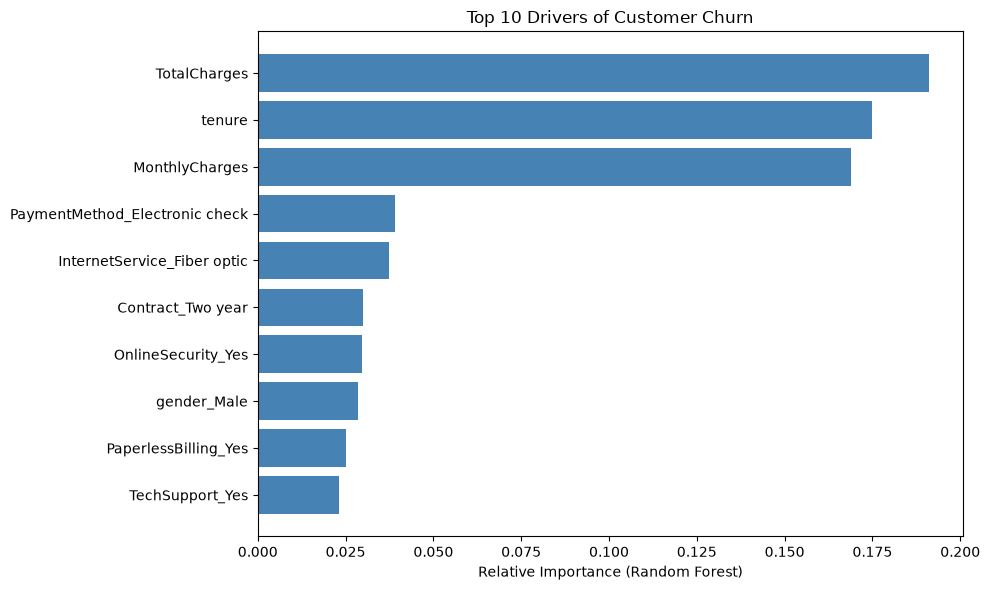

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)
log_preds = log_model.predict(X_test_scaled)
log_probs = log_model.predict_proba(X_test_scaled)[:, 1]

# 2. Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

# 3. Evaluate Models (ROC-AUC handles imbalanced churn data better than raw accuracy)
print("--- Logistic Regression Performance ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, log_probs):.4f}")
print(classification_report(y_test, log_preds))

print("\n--- Random Forest Performance ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")
print(classification_report(y_test, rf_preds))

# 4. Plot Feature Importance (What actually drives Churn)
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-10:] # Get top 10 features
features = X.columns

plt.figure(figsize=(10, 6))
plt.title('Top 10 Drivers of Customer Churn')
plt.barh(range(len(indices)), importances[indices], color='steelblue', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance (Random Forest)')
plt.tight_layout()
plt.show()